# 🌱 Bean Leaf Disease Classification: end-to-end ML pipeline

**Problem.** Beans are a staple food and cash crop for millions of smallholder farmers in East Africa.
Two fungal diseases, **angular leaf spot** and **bean rust**, can cut yields by 40% or more, and
farmers often lack quick access to an agronomist. A model that diagnoses a leaf from a smartphone photo
gives them early, actionable advice.

**Data.** *iBeans*, collected by the Makerere University AI Lab with the National Crops Resources
Research Institute (Uganda). Field photos taken with smartphones, in 3 classes: `angular_leaf_spot`, `bean_rust`, `healthy`.

**This notebook covers:**
1. Data acquisition
2. Data processing (decoding, resizing, augmentation, splits) and feature exploration (3 interpreted features)
3. Model creation (MobileNetV2 transfer learning)
4. Training (head training, then fine-tuning)
5. Model testing with every metric: accuracy, precision, recall, F1, ROC-AUC, log-loss, confusion matrix
6. Prediction functions
7. Retraining (warm start with new data, promoted only if it isn't worse)

All logic lives in `src/` so the notebook, the API and the retraining job share one code path.

In [1]:
import os, sys, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.environ["PROJECT_ROOT"] = str(ROOT)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from src import preprocessing as pp, model as M, prediction as P

sns.set_theme(style="whitegrid")
PALETTE = {"angular_leaf_spot": "#2a78d6", "bean_rust": "#eb6834", "healthy": "#1baf7a"}
print("TensorFlow", tf.__version__)

TensorFlow 2.18.0


## 1. Data acquisition
`download_dataset()` pulls the parquet splits from the Hugging Face mirror and writes JPEGs into `data/train/<class>/` and `data/test/<class>/`. The original *validation* + *test* splits become our **held-out test set**. A validation split for early stopping is carved out of train later.

In [2]:
print(pp.download_dataset())          # skipped if already on disk
counts = pp.dataset_counts()
pd.DataFrame({k: counts[k] for k in ("train", "test")})

{'train': 1070, 'test': 261, 'skipped': True}


,train,test
angular_leaf_spot,357,87
bean_rust,360,88
healthy,353,86


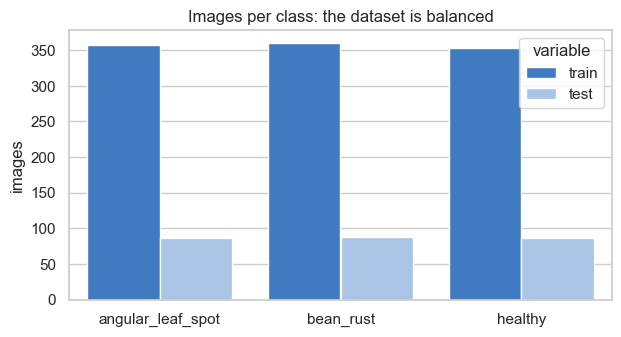

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
df = pd.DataFrame({k: counts[k] for k in ("train", "test")}).reset_index().melt(id_vars="index")
sns.barplot(df, x="index", y="value", hue="variable", ax=ax, palette=["#2a78d6", "#9fc3ee"])
ax.set(xlabel="", ylabel="images", title="Images per class: the dataset is balanced"); plt.show()

**Interpretation:** the classes are balanced (~340 train images each), so accuracy is a fair headline metric and we don't need class weights.

### Look at the raw images

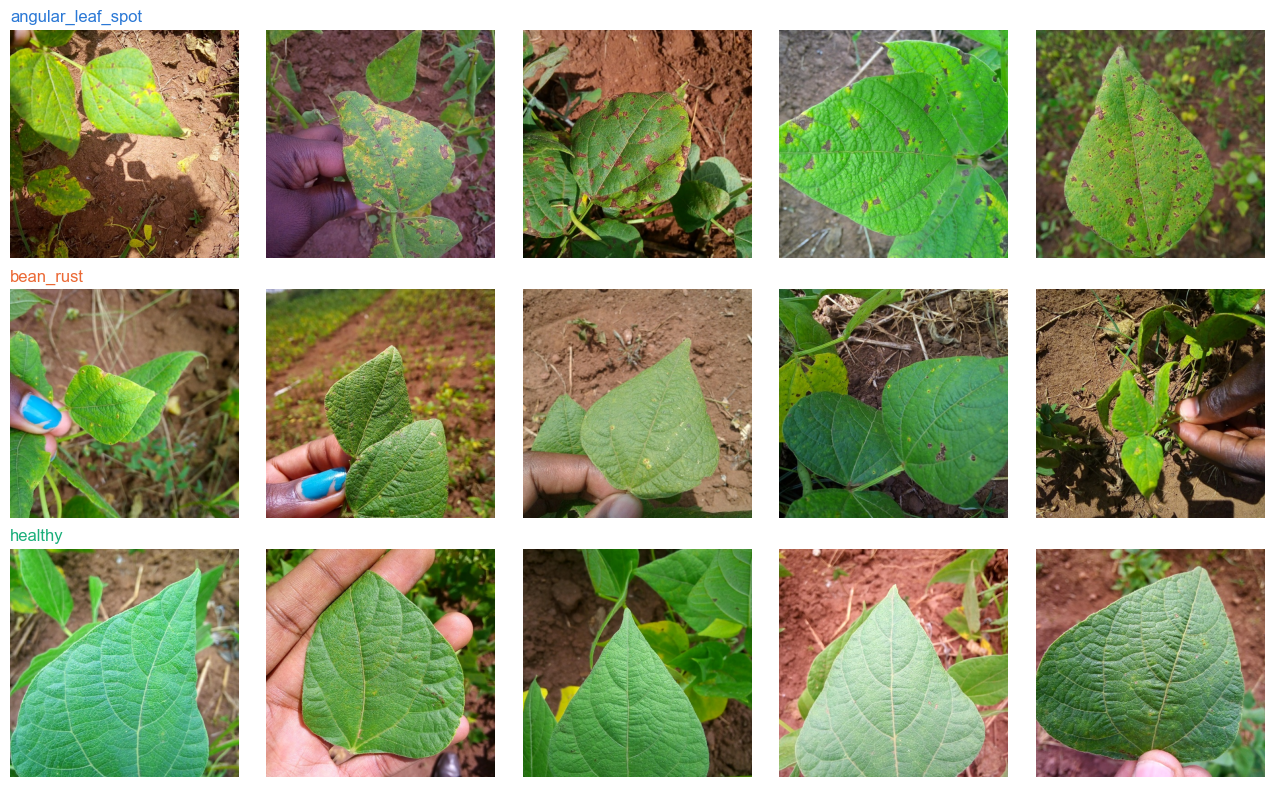

raw image sizes: {(500, 500)}


In [4]:
fig, axes = plt.subplots(3, 5, figsize=(13, 8))
for r, c in enumerate(pp.CLASS_NAMES):
    files = sorted((pp.TRAIN_DIR / c).iterdir())[:5]
    for k, f in enumerate(files):
        axes[r, k].imshow(plt.imread(f)); axes[r, k].axis("off")
        if k == 0: axes[r, k].set_title(c, loc="left", fontsize=12, color=PALETTE[c])
plt.tight_layout(); plt.show()
from PIL import Image
sizes = {Image.open(p).size for p, _ in pp.list_images(pp.TRAIN_DIR)[:200]}
print("raw image sizes:", sizes)

Raw images are 500×500 RGB smartphone photos with busy backgrounds (soil, other leaves, hands) and variable lighting.

## 2. Data processing
Steps (in `src/preprocessing.py`):
1. **Decode** JPEG/PNG to RGB (3 channels), dropping alpha and grayscale variants.
2. **Resize** to 160×160 (MobileNetV2 input; 10× fewer pixels than raw, so much faster on CPU).
3. **Scale** pixels to [-1, 1]. This is done *inside the model* (`Rescaling` layer) so the deployed API can feed raw images.
4. **Stratified split** of train into 85% train and 15% validation (early stopping, LR scheduling).
5. **Augmentation** (train only): random horizontal/vertical flips, ±15% rotation, ±15% zoom, ±15% contrast.
   This copies how farmers actually photograph leaves at any angle and under any light.
6. `tf.data` pipeline with parallel decoding, batching (32) and prefetching.

train 909 | validation 161 | test 261


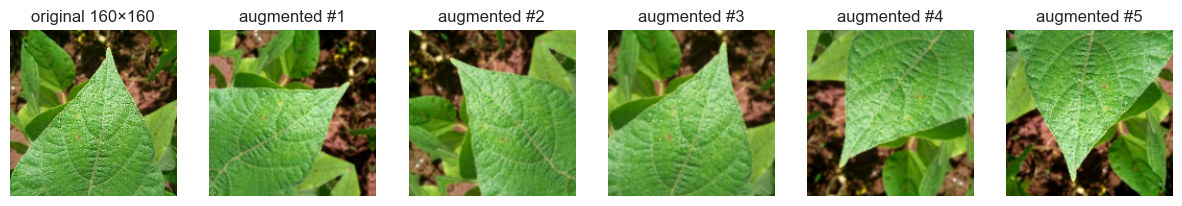

In [5]:
items = pp.list_images(pp.TRAIN_DIR)
tr_items, va_items = pp.stratified_split(items, 0.15, M.SEED)
print(f"train {len(tr_items)} | validation {len(va_items)} | test {len(pp.list_images(pp.TEST_DIR))}")

ds_demo = pp.make_tf_dataset(tr_items[:1], 1)
x, _ = next(iter(ds_demo)); aug = pp.augmentation_layer()
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(x[0].numpy().astype("uint8")); axes[0].set_title("original 160×160")
for i in range(1, 6):
    axes[i].imshow(np.clip(aug(x, training=True)[0].numpy(), 0, 255).astype("uint8")); axes[i].set_title(f"augmented #{i}")
for a in axes: a.axis("off")
plt.show()

### Feature exploration: what makes a leaf diseased?
We compute interpretable features per image (`pp.image_features`): brightness, contrast, mean R/G/B,
**green-pixel ratio**, **brown/lesion-pixel ratio**, edge density.

In [6]:
stats = pp.compute_feature_stats(pp.TRAIN_DIR, save=True)
feat = pd.DataFrame(stats["per_image"])
feat.groupby("label")[["green_ratio", "brown_ratio", "brightness", "contrast", "edge_density", "mean_r", "mean_g", "mean_b"]].mean().round(3)

,green_ratio,brown_ratio,brightness,contrast,edge_density,mean_r,mean_g,mean_b
label,,,,,,,,
angular_leaf_spot,0.427,0.423,125.715,40.396,0.110,128.520,134.373,73.771
bean_rust,0.395,0.413,115.029,40.878,0.126,120.584,119.350,78.209
healthy,0.662,0.235,129.675,40.554,0.121,121.179,142.436,86.254


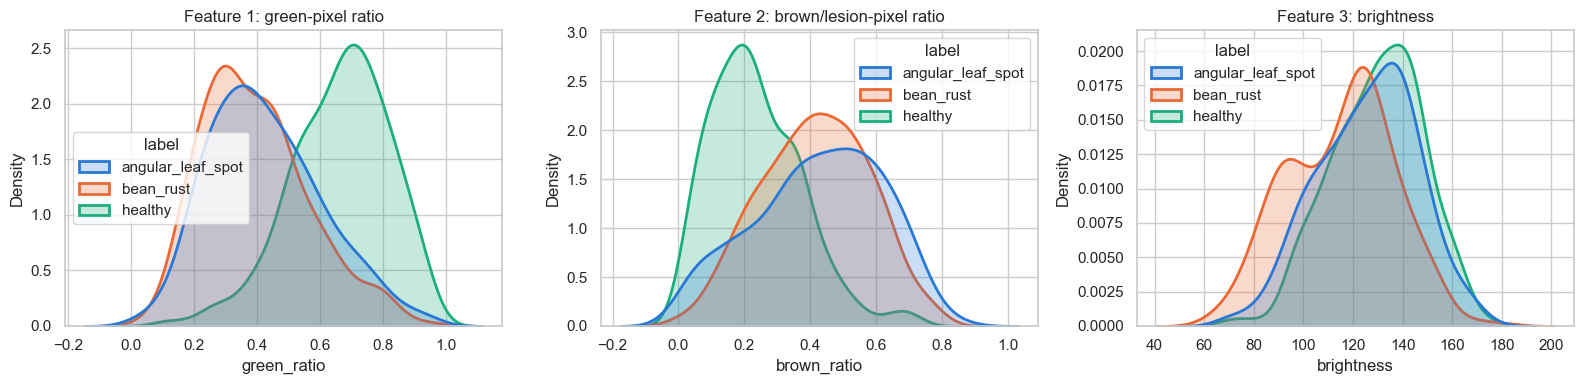

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, f, t in zip(axes, ["green_ratio", "brown_ratio", "brightness"],
                    ["Feature 1: green-pixel ratio", "Feature 2: brown/lesion-pixel ratio", "Feature 3: brightness"]):
    sns.kdeplot(feat, x=f, hue="label", fill=True, common_norm=False, palette=PALETTE, ax=ax, alpha=.25, linewidth=2)
    ax.set_title(t)
plt.tight_layout(); plt.show()

**Feature 1: green ratio.** Healthy leaves are ~66% clearly-green pixels vs ~40% for diseased leaves.
Both diseases destroy chlorophyll, so lost greenness is the clearest single signal of infection.
On its own it separates *healthy vs sick*, but not leaf spot vs rust.

**Feature 2: brown/lesion ratio.** Diseased leaves have ~1.8× more brown/yellow-brown pixels (necrotic lesions,
rust pustules). The two disease curves overlap almost completely, so colour can't tell the diseases apart.
Healthy images score above zero because soil and stems show in the background, which is why the model needs to
learn *where* the brown is, not just how much there is.

**Feature 3: brightness.** Rust photos are noticeably darker (mean ≈115 vs ≈130) because dense dark-brown pustules
pull luminance down. Brightness also varies with field lighting, a nuisance factor the model must ignore,
so we use contrast augmentation.

**The story:** simple colour statistics flag *that* a leaf is sick but not *which* disease. Telling the two
apart needs spatial patterns (round, raised rust pustules vs angular, vein-bounded leaf-spot lesions), which is
exactly what a convolutional network learns. That motivates the CNN below.

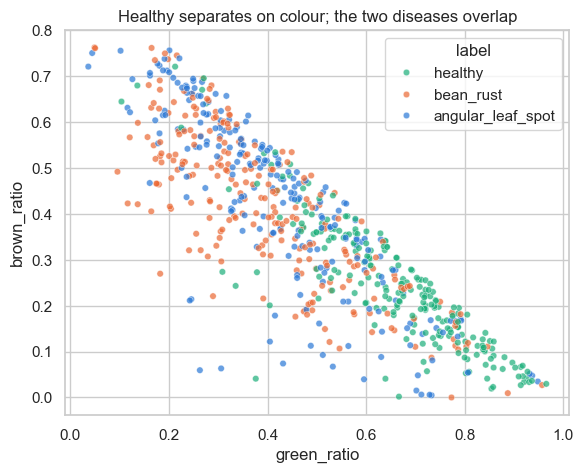

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.scatterplot(feat.sample(700, random_state=0), x="green_ratio", y="brown_ratio", hue="label",
                palette=PALETTE, s=22, alpha=.7, ax=ax)
ax.set_title("Healthy separates on colour; the two diseases overlap"); plt.show()

## 3. Model creation
**Transfer learning with MobileNetV2** (ImageNet weights). It's small (≈2.4M base parameters, 25 MB file), fast on CPU
(~7 ms/image), and well suited to a cheap cloud container and to an eventual phone app.

Head: GlobalAveragePooling → BatchNorm → Dropout(0.3) → Dense(128, ReLU, L2 1e-4) → Dropout(0.3) → Dense(3, softmax).

Optimisation choices:
- **Adam**, LR 1e-3 for the head, then **1e-5** for fine-tuning (so the pretrained features aren't wiped out)
- **EarlyStopping** on val_accuracy (patience 4, restore best weights) to prevent overfitting
- **ReduceLROnPlateau** (×0.5 after 2 stagnant epochs)
- **L2 + dropout** regularisation, and **augmentation** as data-level regularisation
- BatchNorm layers stay frozen during fine-tuning (small dataset)

In [9]:
model = M.build_model()
model.summary(line_length=100)

Model: "bean_disease_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)                         │ (None, 160, 160, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ scale_to_-1_1 (Rescaling)                  │ (None, 160, 160, 3)             │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ mobilenetv2_1.00_160 (Functional)          │ (None, 5, 5, 1280)              │         2,257,984 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ global_average_pooling2d                   │ (None, 1280)                    │                 0 │
│ (GlobalAveragePooling2D)                   │                                 │                   │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ batch_normalization (BatchNormalization)   │ (None, 1280)                    │             5,120 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ dropout (Dropout)                          │ (None, 1280)                    │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ dense (Dense)                              │ (None, 128)                     │           163,968 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ dropout_1 (Dropout)                        │ (None, 128)                     │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ probs (Dense)                              │ (None, 3)                       │               387 │
└────────────────────────────────────────────┴─────────────────────────────────┴───────────────────┘

 Total params: 2,427,459 (9.26 MB)

 Trainable params: 166,915 (652.01 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

## 4. Training
Phase 1 trains only the head (base frozen). Phase 2 unfreezes the top 40 layers of MobileNetV2 and fine-tunes at a low learning rate.

In [10]:
t0 = time.time()
model, history = M.train(epochs_head=12, epochs_finetune=8, model=model, progress=print)
print(f"training time: {time.time() - t0:.0f}s")

phase 1: training head on 909 images (161 for validation)
Epoch 1/12


/Users/apple/Library/Application Support/Claude/scratch-workspaces/4a4a1a33-b7c4-4b23-b288-90aef943e6ca/4df2b8ba-71cb-4e91-b5ee-bfd110eed42d/scratch-2026-11-20-e4ba60/bean_disease_pipeline/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


29/29 - 10s - 337ms/step - accuracy: 0.6711 - loss: 0.9712 - val_accuracy: 0.8075 - val_loss: 0.4968 - learning_rate: 0.0010


Epoch 2/12


29/29 - 5s - 161ms/step - accuracy: 0.8119 - loss: 0.5501 - val_accuracy: 0.8323 - val_loss: 0.4412 - learning_rate: 0.0010


Epoch 3/12


... (22 outputs left out)

29/29 - 5s - 172ms/step - accuracy: 0.8779 - loss: 0.3497 - val_accuracy: 0.9068 - val_loss: 0.2890 - learning_rate: 5.0000e-06


Epoch 8/8


29/29 - 5s - 169ms/step - accuracy: 0.8768 - loss: 0.3510 - val_accuracy: 0.9068 - val_loss: 0.2760 - learning_rate: 5.0000e-06


training time: 79s


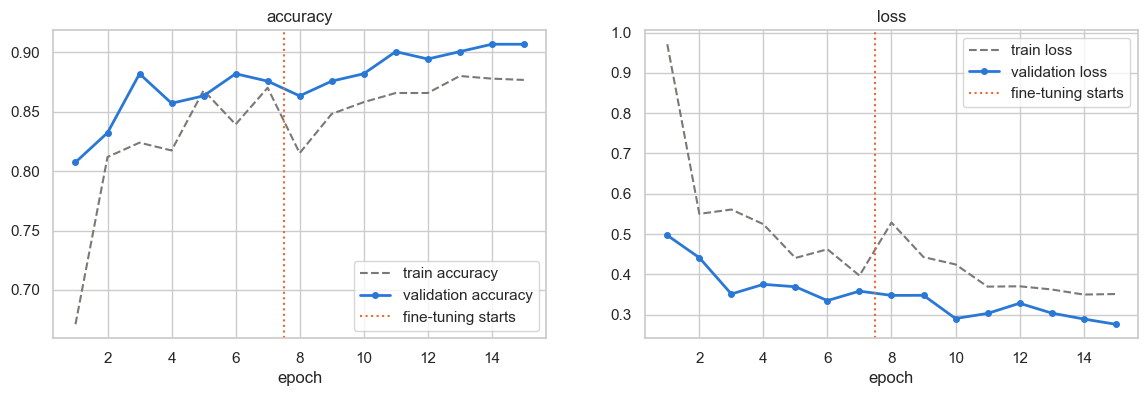

In [11]:
h = pd.DataFrame(history); h["epoch"] = range(1, len(h) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, m in zip(axes, ["accuracy", "loss"]):
    ax.plot(h.epoch, h[m], "--", color="#7a7974", label=f"train {m}")
    ax.plot(h.epoch, h[f"val_{m}"], color="#2a78d6", lw=2, marker="o", ms=4, label=f"validation {m}")
    ft = h.index[h.phase == "finetune"]
    if len(ft): ax.axvline(ft[0] + 0.5, color="#eb6834", ls=":", label="fine-tuning starts")
    ax.set(xlabel="epoch", title=m); ax.legend()
plt.show()

## 5. Model testing: evaluation on the held-out test set
The test images (original validation + test splits, 261 images) were never used for fitting or early stopping.

In [12]:
metrics = M.evaluate(model, pp.TEST_DIR)
pd.Series({k: v for k, v in metrics.items() if isinstance(v, (int, float))}).round(4).to_frame("value")

,value
n_samples,261.0000
accuracy,0.9080
precision_macro,0.9089
recall_macro,0.9083
f1_macro,0.9085
f1_weighted,0.9082
log_loss,0.2563
roc_auc_ovr,0.9811
avg_inference_ms_per_image,6.2787


In [13]:
from sklearn.metrics import classification_report, roc_curve, auc
items_te = pp.list_images(pp.TEST_DIR)
y_true = np.array([y for _, y in items_te])
probs = model.predict(pp.make_tf_dataset(items_te, 32), verbose=0)
y_pred = probs.argmax(1)
print(classification_report(y_true, y_pred, target_names=pp.CLASS_NAMES, digits=4))

                   precision    recall  f1-score   support

angular_leaf_spot     0.9091    0.9195    0.9143        87
        bean_rust     0.8652    0.8750    0.8701        88
          healthy     0.9524    0.9302    0.9412        86

         accuracy                         0.9080       261
        macro avg     0.9089    0.9083    0.9085       261
     weighted avg     0.9085    0.9080    0.9082       261



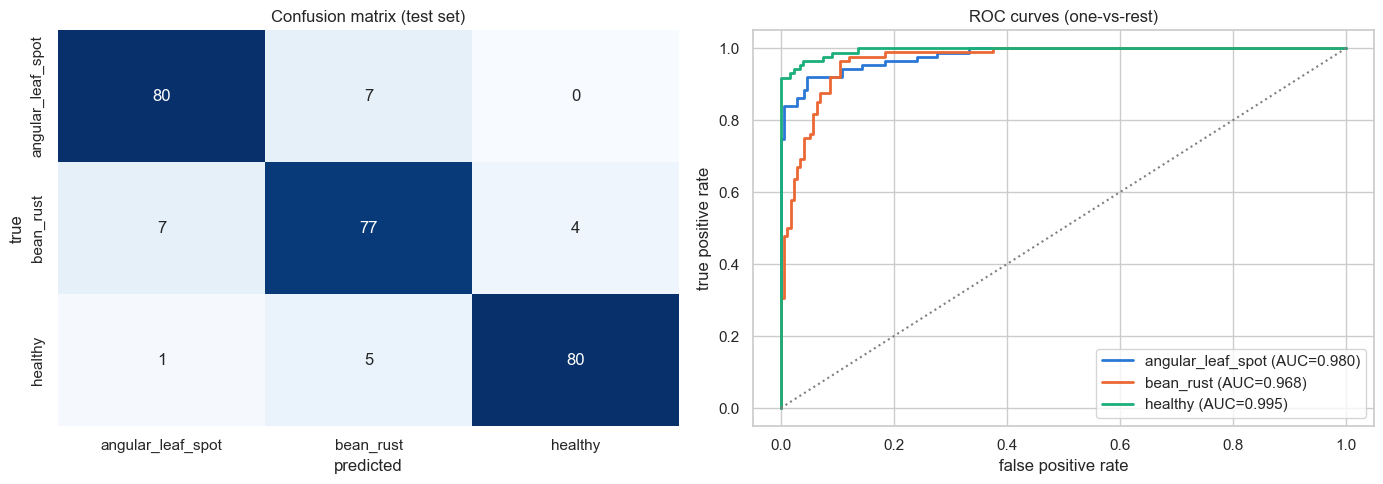

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm = np.array(metrics["confusion_matrix"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=pp.CLASS_NAMES, yticklabels=pp.CLASS_NAMES)
axes[0].set(xlabel="predicted", ylabel="true", title="Confusion matrix (test set)")
for i, c in enumerate(pp.CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_true == i, probs[:, i])
    axes[1].plot(fpr, tpr, lw=2, color=PALETTE[c], label=f"{c} (AUC={auc(fpr, tpr):.3f})")
axes[1].plot([0, 1], [0, 1], ":", color="gray"); axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curves (one-vs-rest)")
axes[1].legend(); plt.tight_layout(); plt.show()

**Reading the results.**
- **Healthy** is recognised best (highest precision). When the model says *healthy* it is almost always right, so few sick crops are missed.
- Most errors are **leaf spot ↔ rust** confusions, which matches the feature analysis: both diseases look alike in colour and differ only in lesion shape.
- Very few diseased leaves are called healthy. That's the costly error for a farmer (no treatment), so this is the behaviour we want.
- ROC-AUC ≈ 0.98: the probabilities rank well, so confidence scores are meaningful (the UI shows them).

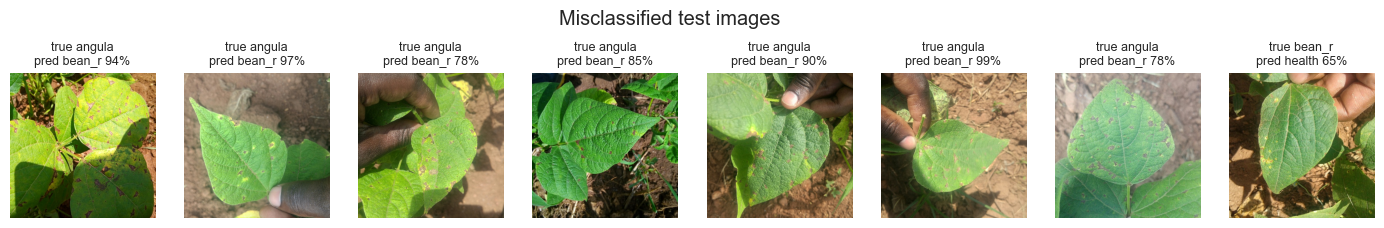

In [15]:
wrong = np.where(y_true != y_pred)[0][:8]
fig, axes = plt.subplots(1, len(wrong), figsize=(2.2 * len(wrong), 2.8))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(plt.imread(items_te[i][0])); ax.axis("off")
    ax.set_title(f"true {pp.CLASS_NAMES[y_true[i]][:6]}\npred {pp.CLASS_NAMES[y_pred[i]][:6]} {probs[i].max():.0%}", fontsize=9)
plt.suptitle("Misclassified test images"); plt.show()

### Save the model
Saved as `models/bean_disease_mobilenetv2.h5` (Keras HDF5) and registered in `models/registry.json` with its metrics and training history.

In [16]:
entry = M.save_and_register(model, metrics, history, note="notebook training")
print(entry["version"], "->", M.MODEL_PATH.relative_to(ROOT), f"({M.MODEL_PATH.stat().st_size/1e6:.1f} MB)")

v4 -> models/bean_disease_mobilenetv2.h5 (24.8 MB)


## 6. Prediction functions
`src/prediction.py` loads the saved `.h5` once and predicts from raw image bytes, which is the same path the API uses.

In [17]:
predictor = P.Predictor()
for c in pp.CLASS_NAMES:
    f = sorted((pp.TEST_DIR / c).iterdir())[3]
    out = predictor.predict_bytes(f.read_bytes())
    print(f"{c:18s} -> predicted {out['label']:18s} conf={out['confidence']:.3f}  {out['inference_ms']} ms")
print()
print(json.dumps(P.predict_file(sorted((pp.TEST_DIR / 'bean_rust').iterdir())[0]), indent=2))

angular_leaf_spot  -> predicted angular_leaf_spot  conf=0.999  62.76 ms
bean_rust          -> predicted bean_rust          conf=0.808  58.28 ms
healthy            -> predicted healthy            conf=1.000  47.49 ms



{
  "label": "bean_rust",
  "confidence": 0.9996459484100342,
  "probabilities": {
    "angular_leaf_spot": 8.663118933327496e-05,
    "bean_rust": 0.9996459484100342,
    "healthy": 0.000267438474111259
  },
  "advice": "Bean rust (Uromyces appendiculatus): remove infected debris, improve air flow, consider a recommended fungicide and plant rust-resistant varieties.",
  "inference_ms": 50.92,
  "model_version": "v4"
}


## 7. Retraining
`M.retrain()` is what the API's **Retrain** button and the automatic triggers call:
1. move newly uploaded images from `data/uploads/<class>/` into `data/train/`
2. **warm-start from the production model** (custom pre-trained weights), so it isn't trained from scratch
3. head training, then fine-tuning on the enlarged dataset
4. evaluate on the untouched test set and **promote only if accuracy ≥ production − 1%**

Retraining triggers in the deployed API:
- **Manual**: the "Retrain" button (`POST /retrain`)
- **Data volume**: automatic once ≥ `RETRAIN_THRESHOLD` (30) new labelled images have been uploaded
- **Performance drift**: `POST /model/evaluate` scores the live model on fresh labelled field data; if accuracy falls below 80%, those images are saved and retraining starts

Demo: upload the sample zip (flipped/rotated field photos) and retrain.

In [18]:
import zipfile
zpath = ROOT / "sample_data" / "sample_upload.zip"
if zpath.exists():
    with zipfile.ZipFile(zpath) as zf:
        files = [(n, zf.read(n)) for n in zf.namelist() if not n.endswith("/")]
    print(pp.save_uploaded_images([("sample_upload.zip", zpath.read_bytes())], None))
    print("pending uploads:", pp.pending_upload_count())

{'saved': {'angular_leaf_spot': 12, 'bean_rust': 12, 'healthy': 12}, 'total_saved': 36, 'rejected': []}
pending uploads: 36


In [19]:
entry = M.retrain(epochs_head=3, epochs_finetune=3, progress=print)
print({k: entry[k] for k in ("version", "promoted", "previous_accuracy", "new_images")}, "new accuracy:", round(entry["metrics"]["accuracy"], 4))

merged 36 uploaded images into the training set
warm-starting from production model v4


phase 1: training head on 940 images (166 for validation)
Epoch 1/3


/Users/apple/Library/Application Support/Claude/scratch-workspaces/4a4a1a33-b7c4-4b23-b288-90aef943e6ca/4df2b8ba-71cb-4e91-b5ee-bfd110eed42d/scratch-2026-11-20-e4ba60/bean_disease_pipeline/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


30/30 - 6s - 212ms/step - accuracy: 0.8777 - loss: 0.3468 - val_accuracy: 0.9096 - val_loss: 0.2591 - learning_rate: 3.0000e-04


Epoch 2/3


30/30 - 4s - 140ms/step - accuracy: 0.8830 - loss: 0.3387 - val_accuracy: 0.9157 - val_loss: 0.2604 - learning_rate: 3.0000e-04


... (7 outputs left out)

30/30 - 5s - 167ms/step - accuracy: 0.8968 - loss: 0.3214 - val_accuracy: 0.9277 - val_loss: 0.2207 - learning_rate: 1.0000e-05


evaluating candidate on held-out test set


candidate v5 accuracy=0.9119 (prev=0.9080459770114943) -> PROMOTED


{'version': 'v5', 'promoted': True, 'previous_accuracy': 0.9080459770114943, 'new_images': 36} new accuracy: 0.9119


In [20]:
reg = json.loads(M.REGISTRY_PATH.read_text())
pd.DataFrame([{"version": v["version"], "note": v["note"], "accuracy": v["metrics"]["accuracy"],
               "f1_macro": v["metrics"]["f1_macro"], "promoted": v["promoted"]} for v in reg["versions"]]).round(4)

,version,note,accuracy,f1_macro,promoted
0,v1,initial training,0.8966,0.8975,True
1,v2,retrain with 0 new images,0.8927,0.8936,True
2,v3,retrain with 36 new images,0.9042,0.9051,True
3,v4,notebook training,0.9080,0.9085,True
4,v5,retrain with 36 new images,0.9119,0.9119,True


## Conclusion
- MobileNetV2 transfer learning reaches **~90% accuracy, ~0.90 macro-F1 and ~0.98 ROC-AUC** on 261 unseen field photos, at ~7 ms per image on CPU.
- Colour features alone separate healthy from diseased leaves. Telling the diseases apart needs the CNN's spatial features.
- The pipeline is retrainable: new data → warm-start retrain → gated promotion → hot reload in every API container.